# Kairos: demostración del prototipo (avance del tercer corte)

**Kairos** es un agente que recibe las tareas pendientes de un estudiante (duración estimada, fecha límite y prioridad) y su horario fijo (clases, trabajo, transporte), y propone **en qué bloque hacer cada tarea**. Siempre respeta las restricciones y busca cubrir la mayor prioridad posible.

Este cuaderno muestra:
1. Los datos de entrada.
2. Por qué una regla simple no basta (dos casos didácticos).
3. El plan de una semana de ejemplo con las cuatro estrategias.
4. Las alertas de tareas que no caben.
5. Las comprobaciones automáticas.
6. Los resultados del experimento con 100 semanas sintéticas.
7. Qué dicen esos resultados y qué no.
8. El dataset seleccionado para el módulo de aprendizaje y una primera comparación de modelos.

> **Importante:** la semana de ejemplo y los escenarios del experimento son **sintéticos** (los construyó el equipo). Sirven para comparar estrategias, **no** para sacar conclusiones sobre estudiantes reales. El dataset de la sección 8 sí es real y público, pero es de una sola persona que no es estudiante.

## 0. Preparación

- **En Google Colab:** cambien `REPO_URL` por la dirección de su repositorio y ejecuten la celda. Si todavía no lo han subido a GitHub, suban `kairos.zip` con el panel de archivos (ícono de carpeta) y ejecuten la celda igual.
- **En su computador:** abran el cuaderno desde la carpeta del proyecto. No hay que cambiar nada.

In [ ]:
import os
import subprocess
import sys

REPO_URL = "https://github.com/JUSHEP/kairos.git"   # <- cambiar por la URL real del repositorio
EN_COLAB = "google.colab" in sys.modules

if EN_COLAB and not os.path.isdir("kairos_repo"):
    if os.path.exists("kairos.zip"):
        subprocess.run(["unzip", "-q", "kairos.zip", "-d", "kairos_repo"], check=True)
    else:
        subprocess.run(["git", "clone", "-q", REPO_URL, "kairos_repo"], check=True)
if EN_COLAB:
    os.chdir("kairos_repo/kairos" if os.path.isdir("kairos_repo/kairos/kairos") else "kairos_repo")
elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")                                     # trabajar desde la raíz del proyecto
sys.path.insert(0, os.getcwd())
print("Carpeta de trabajo:", os.getcwd())

Carpeta de trabajo: /home/claude/kairos


In [2]:
import pandas as pd
from IPython.display import Image, display

from kairos.datos import cargar_problema
from kairos.escenarios import caso_fecha_limite_falla, caso_prioridad_falla, generar_instancia_diminuta
from kairos.busqueda import planificar_fuerza_bruta, planificar_optimo
from kairos.metricas import evaluar, valor_plan
from kairos.planificador import ESTRATEGIAS, NOMBRES, resolver
from kairos.reporte import explicar_no_programadas, tabla_plan
from kairos.restricciones import validar_plan
from kairos.visualizacion import dibujar_plan

pd.set_option("display.max_colwidth", 80)

## 1. Datos de entrada

Kairos lee tres archivos de una carpeta (aquí, `datos/ejemplo`):
- `tareas.csv`: qué hay que hacer, cuánto cree el estudiante que dura, para cuándo es y qué tan importante es (1 a 5).
- `bloques_fijos.csv`: compromisos que no se mueven y se repiten cada semana.
- `configuracion.json`: el horizonte (desde el lunes 26/10, 7 días) y las reglas de bienestar. No se programan tareas antes de las 7:00 ni después de las 22:00, se permiten máximo 5 h de tareas por día y hay 30 min de descanso entre tareas del mismo día.

In [3]:
problema = cargar_problema("datos/ejemplo")
tareas = pd.read_csv("datos/ejemplo/tareas.csv")
print(f"{len(problema.tareas)} tareas | {sum(problema.dur) * problema.minutos_por_bloque / 60:.1f} h pedidas | {problema.horas_libres():.1f} h libres en la semana")
tareas

12 tareas | 21.0 h pedidas | 51.0 h libres en la semana


,id,nombre,tipo,duracion_min,fecha_limite,prioridad
0,T1,Estudiar para el quiz de Programación,estudio,120,2026-10-27 07:00,4
1,T2,Lectura de Inglés,lectura,60,2026-10-27 10:00,2
2,T3,Estudiar parcial de Física (parte 1),estudio,120,2026-10-28 09:00,5
3,T4,Estudiar parcial de Física (parte 2),estudio,120,2026-10-28 09:00,5
4,T5,Taller de Cálculo,taller,120,2026-10-28 07:00,4
5,T6,Avance del proyecto de IA,proyecto,180,2026-10-29 10:00,5
6,T7,Ejercicios de Programación,taller,90,2026-10-29 07:00,3
7,T8,Informe de laboratorio de Física,informe,150,2026-10-30 23:59,3
8,T9,Trámite de matrícula en línea,otro,30,2026-10-30 17:00,4
9,T10,Repasar Cálculo,estudio,90,2026-11-01 22:00,2


## 2. ¿Por qué no basta una regla simple?

Una **regla voraz** ordena las tareas con un criterio y pone cada una en el primer hueco donde quepa, sin volver atrás. Se probaron tres:
- **prioridad:** primero lo más importante;
- **fecha límite:** primero lo más urgente;
- **prioridad/duración:** la regla de la primera entrega.

Los dos casos siguientes son mínimos y están hechos a mano. En cada uno falla una regla distinta. La búsqueda exacta acierta en ambos porque revisa todas las combinaciones que importan.

In [4]:
def comparar(problema, optimo=None):
    filas = []
    for e in ESTRATEGIAS:
        r = resolver(problema, e)
        plan = ", ".join(f"{f['tarea']} ({f['día']} {f['inicio']}-{f['fin']})" for f in tabla_plan(problema, r.plan))
        filas.append({"estrategia": NOMBRES[e], "valor (suma de prioridades)": valor_plan(problema, r.plan),
                      "plan": plan or "-"})
    return pd.DataFrame(filas)

print("Caso 1: lunes y martes libres de 18:00 a 22:00.")
print("  Proyecto final: 3 h, prioridad 5, para el martes. Taller: 3 h, prioridad 3, para el lunes.")
display(comparar(caso_prioridad_falla()))
print("Caso 2: lunes libre de 18:00 a 22:00.")
print("  Ejercicios opcionales: 3 h, prioridad 1, para las 21:00. Estudiar parcial: 3 h, prioridad 5, para las 22:00.")
display(comparar(caso_fecha_limite_falla()))

Caso 1: lunes y martes libres de 18:00 a 22:00.
  Proyecto final: 3 h, prioridad 5, para el martes. Taller: 3 h, prioridad 3, para el lunes.


,estrategia,valor (suma de prioridades),plan
0,Voraz: prioridad,5,Proyecto final (lun 26/10 18:00-21:00)
1,Voraz: fecha límite,8,"Taller para el martes (lun 26/10 18:00-21:00), Proyecto final (mar 27/10 18:..."
2,Voraz: prioridad/duración,5,Proyecto final (lun 26/10 18:00-21:00)
3,Búsqueda exacta (BPP + memoria),8,"Taller para el martes (lun 26/10 18:00-21:00), Proyecto final (mar 27/10 18:..."


Caso 2: lunes libre de 18:00 a 22:00.
  Ejercicios opcionales: 3 h, prioridad 1, para las 21:00. Estudiar parcial: 3 h, prioridad 5, para las 22:00.


,estrategia,valor (suma de prioridades),plan
0,Voraz: prioridad,5,Estudiar para el parcial (lun 26/10 18:00-21:00)
1,Voraz: fecha límite,1,Ejercicios opcionales (lun 26/10 18:00-21:00)
2,Voraz: prioridad/duración,5,Estudiar para el parcial (lun 26/10 18:00-21:00)
3,Búsqueda exacta (BPP + memoria),5,Estudiar para el parcial (lun 26/10 18:00-21:00)


## 3. Plan de la semana de ejemplo

Es una semana pesada, con parcial de Física el miércoles a las 9:00. Se ejecutan las cuatro estrategias y se comparan con métricas del **sistema**:
- **violaciones**: restricciones incumplidas; debe ser 0.
- **valor**: suma de prioridades de lo programado.
- **prioridad cubierta**: el valor dividido entre la suma de todas las prioridades.
- **brecha**: cuánto valor se pierde frente al óptimo.
- **tiempo** de cómputo.

In [5]:
resultados = {e: resolver(problema, e) for e in ESTRATEGIAS}
optimo = valor_plan(problema, resultados["busqueda_exacta"].plan)
tabla = pd.DataFrame([evaluar(problema, r, optimo) for r in resultados.values()])
tabla["estrategia"] = tabla["estrategia"].map(NOMBRES)
tabla[["estrategia", "violaciones", "valor", "prioridad_cubierta_pct", "tareas_programadas", "brecha_pct", "tiempo_ms"]]

,estrategia,violaciones,valor,prioridad_cubierta_pct,tareas_programadas,brecha_pct,tiempo_ms
0,Voraz: prioridad,0,31,75.6,9,8.8,0.365
1,Voraz: fecha límite,0,31,75.6,10,8.8,0.333
2,Voraz: prioridad/duración,0,30,73.2,9,11.8,0.343
3,Búsqueda exacta (BPP + memoria),0,34,82.9,10,0.0,187.693


,día,inicio,fin,tarea,prioridad,fecha límite
0,lun 26/10,11:00,12:00,Lectura de Inglés,2,mar 27/10 10:00
1,lun 26/10,19:00,19:30,Trámite de matrícula en línea,4,vie 30/10 17:00
2,lun 26/10,20:00,22:00,Estudiar para el quiz de Programación,4,mar 27/10 07:00
3,mar 27/10,14:00,15:00,Gimnasio,1,dom 01/11 22:00
4,mar 27/10,15:30,17:30,Estudiar parcial de Física (parte 1),5,mié 28/10 09:00
5,mar 27/10,18:00,20:00,Estudiar parcial de Física (parte 2),5,mié 28/10 09:00
6,mié 28/10,19:00,22:00,Avance del proyecto de IA,5,jue 29/10 10:00
7,jue 29/10,14:00,15:30,Repasar Cálculo,2,dom 01/11 22:00
8,jue 29/10,16:00,18:30,Informe de laboratorio de Física,3,vie 30/10 23:59
9,vie 30/10,15:00,17:00,Preparar exposición de Inglés,3,dom 01/11 22:00


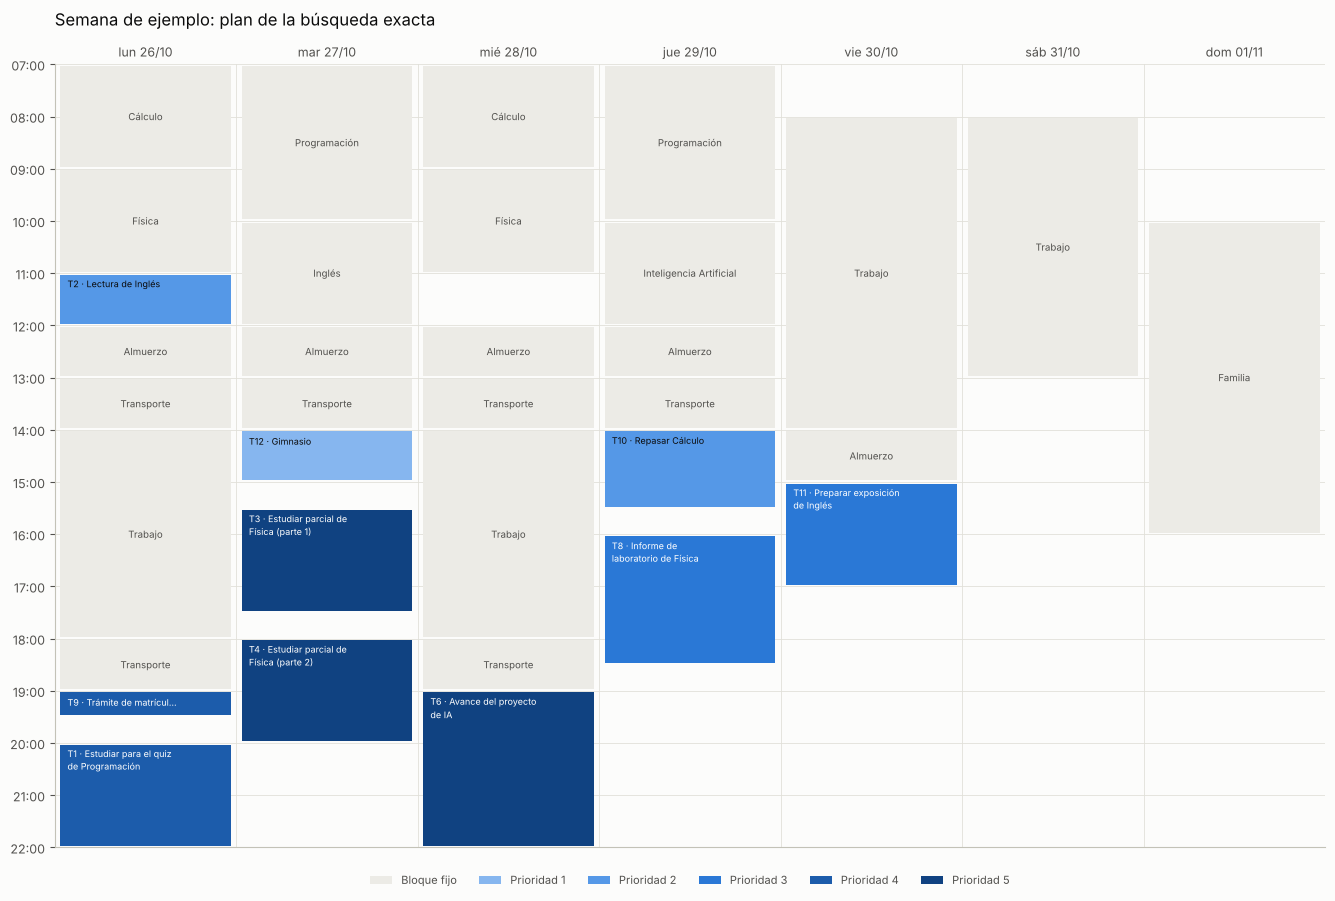

In [6]:
plan = resultados["busqueda_exacta"].plan
display(pd.DataFrame(tabla_plan(problema, plan)))
dibujar_plan(problema, plan, "Semana de ejemplo: plan de la búsqueda exacta");

## 4. Alertas: lo que no cabe y por qué

El agente no solo propone un plan. También **avisa** qué tareas no caben y si el problema es de plazo (no cabría ni sola) o de competencia con tareas más importantes.

In [7]:
pd.DataFrame(explicar_no_programadas(problema, plan))

,tarea,prioridad,duración (min),motivo
0,Taller de Cálculo,4,120,"Cabe sola, pero no junto con tareas de mayor valor. Opciones: liberar tiempo..."
1,Ejercicios de Programación,3,90,"Cabe sola, pero no junto con tareas de mayor valor. Opciones: liberar tiempo..."


## 5. Comprobaciones

1. **Validador independiente.** `validar_plan` revisa desde cero las cuatro restricciones duras (disponibilidad, no solapamiento con descanso, fecha límite y carga diaria), sin confiar en el algoritmo que hizo el plan.
2. **Exacta contra fuerza bruta.** En instancias diminutas, la fuerza bruta prueba **todas** las horas de inicio posibles. Si la búsqueda exacta da el mismo valor, se confirma que poner cada tarea "lo antes posible" (sin cambiar el orden) no hace perder el óptimo.

In [8]:
for e, r in resultados.items():
    print(f"{NOMBRES[e]:35s} violaciones: {len(validar_plan(problema, r.plan))}")

iguales = 0
for semilla in range(100):
    p = generar_instancia_diminuta(semilla)
    exacto, _ = planificar_optimo(p)
    iguales += valor_plan(p, exacto) == valor_plan(p, planificar_fuerza_bruta(p))
print(f"\nInstancias diminutas donde exacta = fuerza bruta: {iguales} de 100")

Voraz: prioridad                    violaciones: 0
Voraz: fecha límite                 violaciones: 0
Voraz: prioridad/duración           violaciones: 0
Búsqueda exacta (BPP + memoria)     violaciones: 0

Instancias diminutas donde exacta = fuerza bruta: 100 de 100


## 6. Experimento: 100 semanas sintéticas

`experimentos/comparar_algoritmos.py` genera 20 semanas por cada tamaño (4, 6, 8, 10 y 12 tareas) y compara las estrategias. Después mide cuánto tarda la búsqueda exacta al crecer el número de tareas. Los resultados quedan en `resultados/`. Volver a correrlo toma alrededor de un minuto: `!python experimentos/comparar_algoritmos.py`.

In [9]:
resumen = pd.read_csv("resultados/resumen_global.csv")
resumen["estrategia"] = resumen["estrategia"].map(NOMBRES)
resumen[["estrategia", "escenarios", "violaciones", "prioridad_cubierta_media", "brecha_media", "brecha_max",
         "pct_escenarios_optimos", "tiempo_ms_mediana"]]

,estrategia,escenarios,violaciones,prioridad_cubierta_media,brecha_media,brecha_max,pct_escenarios_optimos,tiempo_ms_mediana
0,Búsqueda exacta (BPP + memoria),100,0,93.71,0.00,0.0,100.0,2.72
1,Voraz: fecha límite,100,0,90.88,3.26,25.0,67.0,0.13
2,Voraz: prioridad,100,0,86.40,7.88,25.0,27.0,0.12
3,Voraz: prioridad/duración,100,0,83.94,10.69,37.5,23.0,0.10


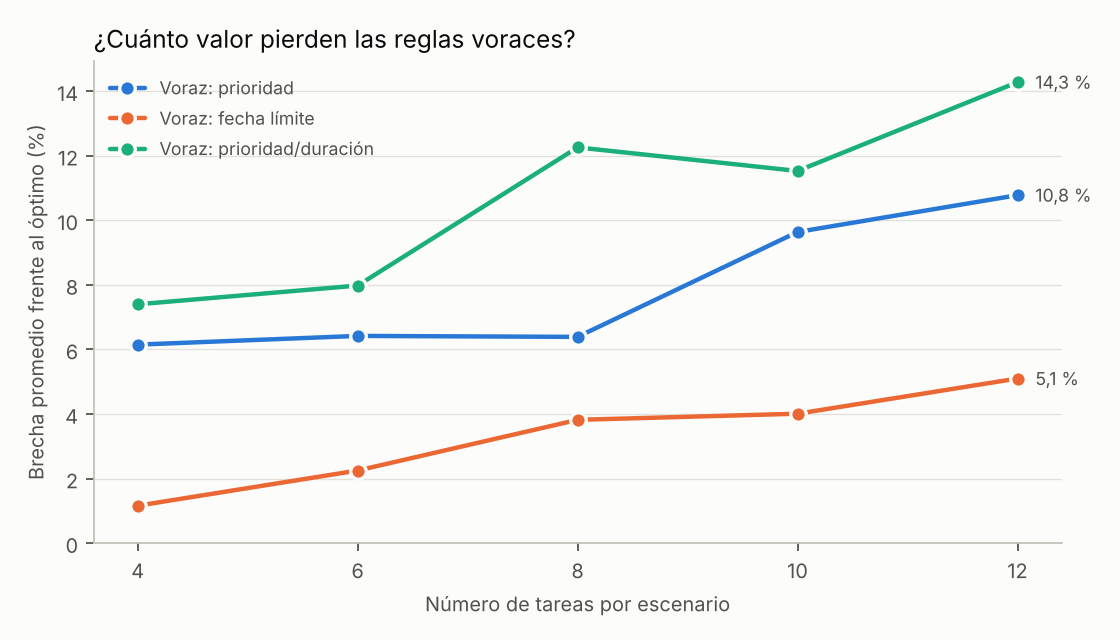

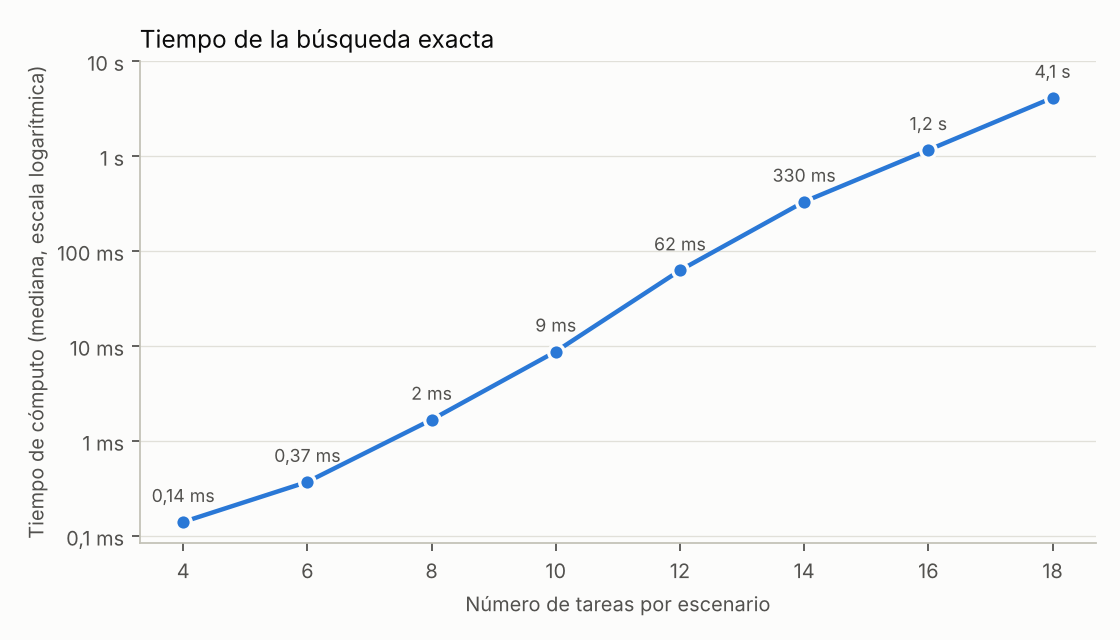

,median,max
n_tareas,,
4,0.1,0.2
6,0.4,0.8
8,1.7,3.3
10,8.7,22.7
12,62.4,196.4
14,330.2,1384.3
16,1155.8,8678.2
18,4097.0,24289.2


In [10]:
display(Image("resultados/brecha_voraces.png", width=650))
display(Image("resultados/tiempo_busqueda_exacta.png", width=650))
pd.read_csv("resultados/escalabilidad.csv").groupby("n_tareas")["tiempo_ms"].agg(["median", "max"]).round(1)

## 7. Qué dicen estos resultados (y qué no)

**Lo que muestran (en escenarios sintéticos):**
- Ningún plan de ninguna estrategia violó restricciones.
- La regla por fecha límite fue la mejor de las voraces, pero en un tercio de los escenarios ninguna regla voraz llegó al óptimo, y la pérdida crece con el número de tareas.
- La regla de la primera entrega (prioridad/duración) fue la que más valor perdió.
- Con hasta 12 tareas (una semana típica de estudiante), la búsqueda exacta tardó menos de medio segundo en todos los escenarios. Su tiempo crece de forma exponencial: con 18 tareas la mediana ya ronda los 4 s y el peor caso medido, unos 24 s.

**Lo que NO muestran:**
- Que estos planes sean útiles para estudiantes reales. Eso requiere probarlo con usuarios.
- Que las duraciones estimadas sean correctas. El prototipo asume que el estudiante acierta, y por eso el siguiente módulo busca aprender la duración real a partir de su historial.

## 8. Dataset seleccionado para el módulo de aprendizaje

El planificador usa la duración que el estudiante estima, y la gente suele quedarse corta (falacia de planificación). Por eso el siguiente módulo aprenderá del historial **cuánto dura de verdad una tarea**. Es un problema de **regresión**: la salida es un número.

**Dataset seleccionado: Renzo Pomodoro dataset** (Jones y Borgatti, 2019). Una persona planeó sus tareas del día entre 2009 y 2019. Estimaba cada tarea en pomodoros (bloques de 25 minutos de trabajo) y después anotaba cuántos gastó. Es la misma decisión que toma Kairos: cuántos bloques reservar para cada tarea.

- **Fuente:** https://github.com/Derek-Jones/renzo-pomodoro. Es público, pero el repositorio no declara licencia. Por eso lo usamos solo con fines académicos, citando la fuente, y no lo subimos a nuestro repositorio: se descarga al ejecutar.
- **Columnas que usamos:** fecha, pomodoros estimados, pomodoros reales, si la tarea se terminó y la etiqueta del tipo de tarea (por ejemplo `@planning`).
- **Límite principal:** es **una sola persona** y no es estudiante. Sirve para construir y probar el módulo. Para estudiantes hay que recolectar datos propios con las mismas variables; la plantilla `datos/plantillas/registro_duraciones.csv` ya las tiene, en minutos.

La primera vez, la celda descarga el archivo (necesita internet).

In [11]:
from kairos.duraciones import (cargar_pomodoro, coeficientes_regresion_simple, comparar_modelos,
                               particion_temporal, preparar, resumen, tabla_por_estimacion)
from kairos.visualizacion import dibujar_real_vs_estimado

original = cargar_pomodoro()
x = preparar(original)   # tareas terminadas, con estimado y real mayores que cero, sin duplicados
print(f"Filas originales: {len(original)} | tareas terminadas con estimado y real: {len(x)}")
pd.Series(resumen(x))

Filas originales: 17764 | tareas terminadas con estimado y real: 7274


tareas                                   7274
dias_distintos                           1905
desde                              2009-04-09
hasta                              2019-02-07
etiquetas_distintas                       203
pct_exacta                               53.3
pct_se_paso                              27.2
pct_sobro_tiempo                         19.6
real_total_sobre_estimado_total         1.106
dtype: object

,estimado,tareas,real_promedio,real_mediana
0,0.5,2,0.50,0.5
1,1.0,3501,1.41,1.0
2,2.0,2166,2.27,2.0
3,3.0,341,2.93,3.0
4,4.0,1029,3.77,3.0
5,5.0,55,4.65,5.0
6,6.0,130,5.23,5.0
7,7.0,3,6.00,4.0
8,8.0,42,5.95,6.0
9,9.0,1,4.00,4.0


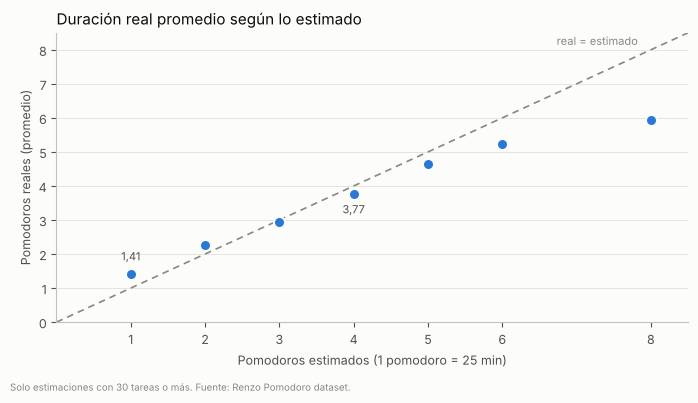

In [12]:
tabla_pom = tabla_por_estimacion(x)
display(tabla_pom)
dibujar_real_vs_estimado(tabla_pom);

**Primera comparación de modelos.** Se entrena con las tareas anteriores al 6 de noviembre de 2014 (cerca del 75 %) y se prueba con las posteriores. Es una **partición temporal**: el modelo nunca aprende del futuro. El valor de k del k-NN se elige con una validación dentro del entrenamiento, sin mirar la prueba.

Métricas:
- **MAE** (error absoluto medio), en pomodoros y en minutos. Es la principal porque se entiende directo: "en promedio se equivoca por tantos minutos".
- **MSE** (error cuadrático medio): castiga más los errores grandes.
- **% que cabe en lo reservado:** si Kairos reserva la predicción redondeada a bloques completos, qué porcentaje de tareas termina dentro de ese tiempo. Es lo que le importa al planificador.
- **Reservado sobre real:** tiempo reservado dividido entre el tiempo usado. Más de 1 significa que se reserva de más.

In [13]:
entrenamiento, prueba = particion_temporal(x)
a, b = coeficientes_regresion_simple(entrenamiento)
print(f"Entrenamiento: {len(entrenamiento)} tareas | prueba: {len(prueba)} tareas")
print(f"Regresión lineal simple aprendida: real = {a:.2f} + {b:.2f} x estimado")
comparar_modelos(entrenamiento, prueba)

Entrenamiento: 5453 tareas | prueba: 1821 tareas
Regresión lineal simple aprendida: real = 0.73 + 0.73 x estimado


,modelo,MAE_pomodoros,MAE_minutos,MSE,pct_caben_en_lo_reservado,reservado_sobre_real
0,Línea base: usar la estimación tal cual,0.896,22.4,2.448,71.4,0.898
1,Regresión lineal: real ~ estimado,1.003,25.1,2.319,84.0,1.212
2,Regresión lineal: real ~ estimado + tipo,0.973,24.3,2.328,83.9,1.205
3,"k-NN (k = 5, elegido con validación): estimado + tipo",0.943,23.6,2.397,79.2,1.115


**Qué dice esta primera prueba (y qué no):**
- Esta persona estima bien: más de la mitad de sus tareas salen exactas. Aun así hay un patrón: **las tareas cortas se le alargan y las largas se le acortan**. Las de 1 pomodoro duraron 1,41 en promedio y las de 4, 3,77.
- En MAE, ningún modelo le gana todavía a usar la estimación tal cual. La regresión baja el MSE (menos errores grandes), pero sube el MAE.
- Para el planificador, la regresión hace que quepan más tareas en lo reservado (84 % frente a 71 %), a cambio de reservar cerca de 21 % más tiempo del que se usa.
- No dice cómo estima un estudiante. En estudiantes se ha medido subestimación sistemática (Buehler et al., 1994), y eso solo lo podemos medir con datos propios. El siguiente paso es aplicar este mismo proceso al registro del equipo (`datos/plantillas/registro_duraciones.csv`).

## 9. Usar sus propios datos

1. Copien la carpeta `datos/ejemplo` a `datos/privados/mi_semana` (la carpeta `datos/privados` no se sube a GitHub).
2. Cambien `tareas.csv` y `bloques_fijos.csv` por su semana real, con el mismo formato.
3. Ejecuten `!python demo.py datos/privados/mi_semana`, o en este cuaderno cambien la ruta en la sección 1.